# **Part A**
Count / Frequency based Naive Bayes Classifier

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# =======================================================
# TODO: Students must implement the following steps:
# 1. Complete the fit method in NaiveBayesClassifier (4 TODOs for log prior and log likelihood calculation).
# 2. Complete the predict method in NaiveBayesClassifier (2 TODOs for log probability accumulation and final argmax).
# 3. Complete the data loading calls in Section 2.
# 4. Initialize CountVectorizer with proper parameters in Section 3a.
# 5. Complete the feature transformation (fit_transform and transform) in Section 3a.
# 6. Initialize and fit the custom nb_model in Section 3b.
# 7. Use the fitted nb_model to generate predictions in Section 4.
# =======================================================


# Data loading function (DO NOT CHANGE)
def load_pubmed_rct_file(filepath):
    """
    Reads a .txt file from the PubMed 20k RCT dataset.
    Returns a DataFrame with 'label' and 'sentence'.
    """
    labels, sentences = [], []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or '\t' not in line:
                continue
            label, sent = line.split('\t', maxsplit=1)
            labels.append(label)
            sentences.append(sent)
    return pd.DataFrame({'label': labels, 'sentence': sentences})


# Implementing Multinomial Naive Bayes from scratch
class NaiveBayesClassifier:
    """
    Multinomial Naive Bayes Classifier implemented from scratch.
    It is suitable for both Count and TF-IDF features.
    """
    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.class_priors = {}
        self.feature_log_probs = {}
        self.classes = None
        self.vocabulary_size = 0

    def fit(self, X_counts, y):
        y_array = y.to_numpy()
        self.classes = np.unique(y_array)
        self.vocabulary_size = X_counts.shape[1]

        for c in self.classes:
            X_c = X_counts[y_array == c]

            # // TODO: Calculate the log prior and store it in self.class_priors[c]
            # Calculate Class Prior P(C): log(P(C))
            # P(C) = (Number of samples in class c) / (Total number of samples)
            self.class_priors[c] = np.log(X_c.shape[0] / X_counts.shape[0])

            feature_sum = X_c.sum(axis=0).A1
            total_mass = np.sum(feature_sum)

            # Apply Laplace smoothing (additive smoothing, alpha=1.0 default):
            # P(w_i | C) = (count(w_i, C) + alpha) / (total_words_in_C + alpha * vocab_size)

            # // TODO: Calculate the numerator (with Laplace smoothing)
            numerator = feature_sum + self.alpha

            # // TODO: Calculate the denominator (with Laplace smoothing)
            denominator = total_mass + self.alpha * self.vocabulary_size

            # // TODO: Calculate the log likelihood (log(numerator / denominator))
            self.feature_log_probs[c] = np.log(numerator / denominator)

    def predict(self, X_counts):
        y_pred = []
        for i in range(X_counts.shape[0]):
            scores = {}

            x_i = X_counts.getrow(i)

            for c in self.classes:
                log_prob = self.class_priors[c]
                log_likelihoods = self.feature_log_probs[c]

                non_zero_indices = x_i.indices
                non_zero_data = x_i.data

                # // TODO: Complete the log probability calculation for the likelihood term
                # Add log likelihoods contribution (Log-Sum Trick):
                # log_prob += sum(count(w_i) * log(P(w_i|C)))
                log_prob += (non_zero_data * log_likelihoods[non_zero_indices]).sum()

                scores[c] = log_prob

            # // TODO: Find the key (class label) with the maximum score
            predicted_class = max(scores, key=scores.get)

            y_pred.append(predicted_class)

        # // TODO: Return the final predictions array
        return np.array(y_pred)


In [3]:
def load_pubmed_rct_file(filepath):
    labels, sentences = [], []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or '\t' not in line:
                continue
            label, sent = line.split('\t', maxsplit=1)
            labels.append(label)
            sentences.append(sent)
    return pd.DataFrame({'label': labels, 'sentence': sentences})


In [4]:
# Load and Prepare Data (DO NOT CHANGE)
data_path = r"C:\Users\melsh\Downloads\Dataset\Dataset"
try:

    train_df = load_pubmed_rct_file(os.path.join(data_path, "train.txt"))
    dev_df   = load_pubmed_rct_file(os.path.join(data_path, "dev.txt"))
    test_df  = load_pubmed_rct_file(os.path.join(data_path, "test.txt"))

    #train_df = pd.DataFrame({'label': ['BACKGROUND'], 'sentence': ['placeholder']})
    #dev_df   = pd.DataFrame({'label': ['BACKGROUND'], 'sentence': ['placeholder']})
    #test_df  = pd.DataFrame({'label': ['BACKGROUND'], 'sentence': ['placeholder']})


    print(f"Train samples: {len(train_df)}")
    print(f"Dev   samples: {len(dev_df)}")
    print(f"Test  samples: {len(test_df)}")

    X_train, y_train = train_df['sentence'], train_df['label']
    X_dev,   y_dev   = dev_df['sentence'],   dev_df['label']
    X_test,  y_test  = test_df['sentence'],  test_df['label']
    target_names = sorted(y_train.unique())
    print(f"Classes: {target_names}")

except FileNotFoundError as e:
    print(f"Error: Dataset file not found. Please ensure the files are uploaded.")
    X_train, y_train = pd.Series([]), pd.Series([])
    X_test, y_test = pd.Series([]), pd.Series([])
    target_names = []

Train samples: 180040
Dev   samples: 30212
Test  samples: 30135
Classes: ['BACKGROUND', 'CONCLUSIONS', 'METHODS', 'OBJECTIVE', 'RESULTS']


In [5]:
# Feature Extraction and Custom Model Training
if X_train is not None and len(X_train) > 0:

    count_vectorizer = CountVectorizer(
        lowercase=True,
        strip_accents='unicode',
        stop_words='english',
        ngram_range=(1,2),   # unigrams + bigrams
        min_df=1,
        max_df=1.0           # important for small datasets
    )

    print("Fitting Count Vectorizer and transforming training data...")
    X_train_counts = count_vectorizer.fit_transform(X_train)

    if X_train_counts is not None:
        print(f"Vocabulary size: {X_train_counts.shape[1]}")

    print("Transforming test data...")
    X_test_counts = count_vectorizer.transform(X_test)

    print("\nTraining the Custom Naive Bayes Classifier (from scratch)...")
    nb_model = NaiveBayesClassifier(alpha=1.0)
    nb_model.fit(X_train_counts, y_train)

    print("Training complete.")

else:
    print("Skipping feature extraction and training: Training data is empty or not loaded.")


Fitting Count Vectorizer and transforming training data...
Vocabulary size: 1108611
Transforming test data...

Training the Custom Naive Bayes Classifier (from scratch)...
Training complete.


In [6]:
# Predict and evaluate on test set
print("\n=== Test Set Evaluation (Custom Count-Based Naive Bayes) ===")

# // TODO: Predict y_test_pred using X_test_counts
y_test_pred = nb_model.predict(X_test_counts)

if y_test_pred is not None:
    print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
    print(classification_report(y_test, y_test_pred, target_names=target_names))
    test_f1 = f1_score(y_test, y_test_pred, average='macro')
    print(f"Macro-averaged F1 score: {test_f1:.4f}")
else:
    print("Prediction step failed or incomplete.")



=== Test Set Evaluation (Custom Count-Based Naive Bayes) ===
Accuracy: 0.7431
              precision    recall  f1-score   support

  BACKGROUND       0.61      0.46      0.53      3621
 CONCLUSIONS       0.65      0.62      0.63      4571
     METHODS       0.74      0.91      0.82      9897
   OBJECTIVE       0.67      0.29      0.41      2333
     RESULTS       0.83      0.84      0.84      9713

    accuracy                           0.74     30135
   macro avg       0.70      0.63      0.64     30135
weighted avg       0.74      0.74      0.73     30135

Macro-averaged F1 score: 0.6446


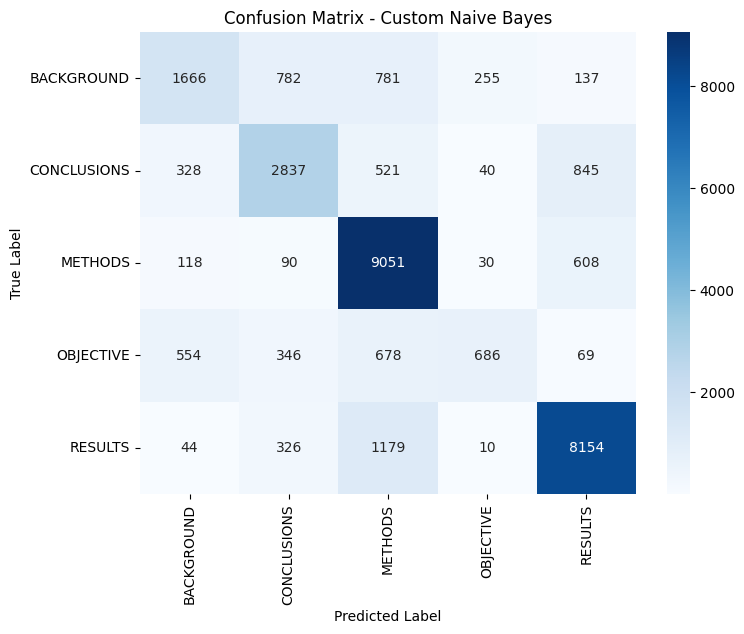

In [7]:
# Confusion Matrix on test set
# // TODO: Use the confusion_matrix, matplotlib, and seaborn libraries to generate
# a visual confusion matrix (heatmap) for the predicted results.
if y_test_pred is not None:
    cm = confusion_matrix(y_test, y_test_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=target_names,
                yticklabels=target_names)

    plt.title("Confusion Matrix - Custom Naive Bayes")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()
else:
    print("Cannot display confusion matrix: predictions not available.")


# **Part B**
TF-IDF score based Classifier

Training initial Naive Bayes pipeline...
Training complete.

=== Test Set Evaluation (Initial Sklearn Model) ===
Accuracy: 0.6996
              precision    recall  f1-score   support

  BACKGROUND       0.61      0.37      0.46      3621
 CONCLUSIONS       0.61      0.55      0.57      4571
     METHODS       0.68      0.88      0.77      9897
   OBJECTIVE       0.72      0.09      0.16      2333
     RESULTS       0.77      0.85      0.81      9713

    accuracy                           0.70     30135
   macro avg       0.68      0.55      0.56     30135
weighted avg       0.69      0.70      0.67     30135

Macro F1: 0.5555

Starting Hyperparameter Tuning on Development Set...
Fitting 2 folds for each of 18 candidates, totalling 36 fits
Grid search complete.

Best Parameters: {'nb__alpha': 0.1, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2)}
Best Dev F1: 0.6167

=== Test Set Evaluation (Tuned Model) ===
Accuracy: 0.7200
              precision    recall  f1-score   support

  BAC

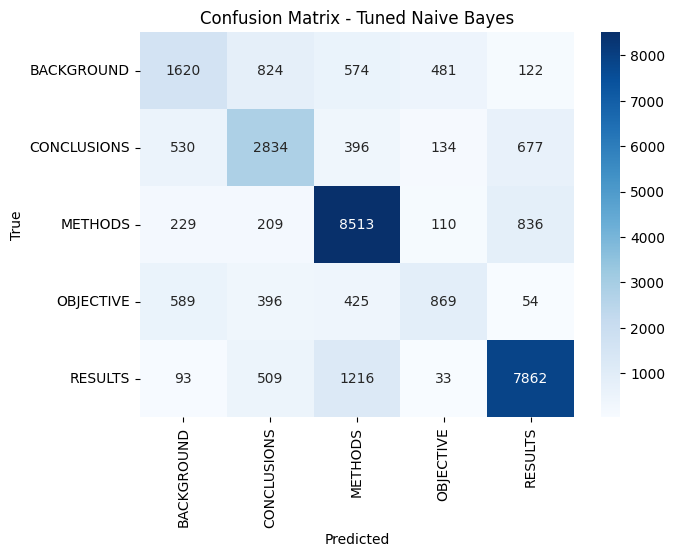

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# =======================================================
# 1. Define Pipeline
# =======================================================
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("nb", MultinomialNB())
])

# =======================================================
# 2. Train Initial Model
# =======================================================
print("Training initial Naive Bayes pipeline...")
pipeline.fit(X_train, y_train)
print("Training complete.")

# =======================================================
# 3. Test Set Evaluation
# =======================================================
print("\n=== Test Set Evaluation (Initial Sklearn Model) ===")
y_test_pred = pipeline.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print(classification_report(y_test, y_test_pred, target_names=target_names))
print(f"Macro F1: {f1_score(y_test, y_test_pred, average='macro'):.4f}")

# =======================================================
# 4. Hyperparameter Grid
# =======================================================
param_grid = {
    "tfidf__ngram_range": [(1,1), (1,2)],
    "tfidf__min_df": [1, 2, 5],
    "nb__alpha": [0.1, 1.0, 2.0]
}

# =======================================================
# 5. Grid Search
# =======================================================
grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=2,                  # ✅ Use 2 folds to avoid ValueError
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

print("\nStarting Hyperparameter Tuning on Development Set...")
grid.fit(X_dev, y_dev)
print("Grid search complete.")

# =======================================================
# 6. Best Results
# =======================================================
print("\nBest Parameters:", grid.best_params_)
print(f"Best Dev F1: {grid.best_score_:.4f}")

# =======================================================
# 7. Evaluate Best Model on Test Set
# =======================================================
print("\n=== Test Set Evaluation (Tuned Model) ===")
best_model = grid.best_estimator_
y_test_pred_best = best_model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_test_pred_best):.4f}")
print(classification_report(y_test, y_test_pred_best, target_names=target_names))
print(f"Macro F1: {f1_score(y_test, y_test_pred_best, average='macro'):.4f}")

# =======================================================
# 8. Confusion Matrix
# =======================================================
cm = confusion_matrix(y_test, y_test_pred_best)

plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names,
            yticklabels=target_names)
plt.title("Confusion Matrix - Tuned Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


# **Part C**
Bayes Optimal Classifier

Part C Draft

Using dynamic sample size: 10160
Actual sampled training size = 10160

Training all base models...


C:\Users\melsh\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


✅ All base models trained.


C:\Users\melsh\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(



Posterior Weights P(h|D):
NaiveBayes: 0.2322
LogisticRegression: 0.2456
RandomForest: 0.2163
DecisionTree: 0.1655
KNN: 0.1405

Fitting Bayes Optimal Classifier...


C:\Users\melsh\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


✅ BOC training complete.

=== BOC Final Evaluation ===
Accuracy: 0.6926
Macro F1: 0.5842
              precision    recall  f1-score   support

  BACKGROUND       0.59      0.29      0.39      3621
 CONCLUSIONS       0.61      0.51      0.56      4571
     METHODS       0.66      0.90      0.76      9897
   OBJECTIVE       0.69      0.29      0.41      2333
     RESULTS       0.79      0.81      0.80      9713

    accuracy                           0.69     30135
   macro avg       0.67      0.56      0.58     30135
weighted avg       0.69      0.69      0.67     30135



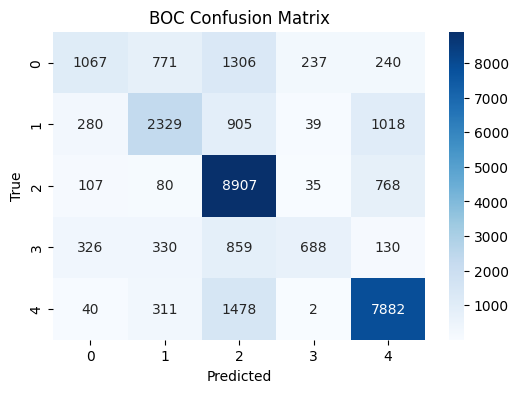

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, log_loss
from sklearn.model_selection import train_test_split

# =======================================================
# Dynamic SRN Based Sampling
# =======================================================
BASE_SAMPLE_SIZE = 10000
FULL_SRN = input("Please enter your full SRN (e.g., PES1UG22CS345): ")

try:
    srn_suffix_str = FULL_SRN[-3:]
    srn_value = int(srn_suffix_str)
except:
    print("WARNING: Invalid SRN. Using default 10000.")
    srn_value = 0

SAMPLE_SIZE = BASE_SAMPLE_SIZE + srn_value
print(f"Using dynamic sample size: {SAMPLE_SIZE}")

# Dummy fallback data if user didn't load actual PubMed dataset earlier
if 'X_train' not in locals() or len(X_train) == 0:
    print("⚠️ Using fallback data (load real dataset earlier!)")
    X_train = pd.Series(["sample text one"] * 11000)
    y_train = pd.Series(["BACKGROUND"] * 5000 + ["METHODS"] * 6000)
    X_test = pd.Series(["test text one", "test text two"])
    y_test = pd.Series(["BACKGROUND", "METHODS"])
    target_names = ["BACKGROUND", "CONCLUSIONS", "METHODS", "OBJECTIVE", "RESULTS"]

effective_sample_size = min(SAMPLE_SIZE, len(X_train))
X_train_sampled = X_train[:effective_sample_size]
y_train_sampled = y_train[:effective_sample_size]
print(f"Actual sampled training size = {effective_sample_size}")

# =======================================================
# Define 5 Models (H1–H5)
# =======================================================
tfidf_params = {
    'lowercase': True,
    'strip_accents': 'unicode',
    'stop_words': 'english',
    'ngram_range': (1, 1),
    'min_df': 5
}

h1_nb = Pipeline([('tfidf', TfidfVectorizer(**tfidf_params)), ('clf', MultinomialNB(alpha=1.0, fit_prior=False))])
h2_lr = Pipeline([('tfidf', TfidfVectorizer(**tfidf_params)), ('clf', LogisticRegression(solver='liblinear', max_iter=1000, random_state=42))])
h3_rf = Pipeline([('tfidf', TfidfVectorizer(**tfidf_params)), ('clf', CalibratedClassifierCV(RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42), cv=3))])
h4_dt = Pipeline([('tfidf', TfidfVectorizer(**tfidf_params)), ('clf', CalibratedClassifierCV(DecisionTreeClassifier(max_depth=10, random_state=42), cv=3))])
h5_knn = Pipeline([('tfidf', TfidfVectorizer(**tfidf_params)), ('clf', CalibratedClassifierCV(KNeighborsClassifier(n_neighbors=5), cv=3))])

hypotheses = [h1_nb, h2_lr, h3_rf, h4_dt, h5_knn]
hypothesis_names = ['NaiveBayes', 'LogisticRegression', 'RandomForest', 'DecisionTree', 'KNN']

# =======================================================
# Train All Models
# =======================================================
print("\nTraining all base models...")
for model in hypotheses:
    model.fit(X_train_sampled, y_train_sampled)
print("✅ All base models trained.")

# =======================================================
# Compute Posterior Weights P(h|D)
# =======================================================
X_sub_train, X_sub_val, y_sub_train, y_sub_val = train_test_split(
    X_train_sampled, y_train_sampled, test_size=0.2, random_state=42
)

log_losses = []
for model in hypotheses:
    model.fit(X_sub_train, y_sub_train)
    y_prob = model.predict_proba(X_sub_val)
    loss = log_loss(y_sub_val, y_prob)
    log_losses.append(loss)

posterior_weights = np.exp(-np.array(log_losses))
posterior_weights = posterior_weights / posterior_weights.sum()

print("\nPosterior Weights P(h|D):")
for name, w in zip(hypothesis_names, posterior_weights):
    print(f"{name}: {w:.4f}")

# =======================================================
# Voting Classifier (BOC Approximation)
# =======================================================
estimators = list(zip(hypothesis_names, hypotheses))
boc_soft_voter = VotingClassifier(estimators=estimators, voting='soft', weights=posterior_weights)

print("\nFitting Bayes Optimal Classifier...")
boc_soft_voter.fit(X_train_sampled, y_train_sampled)
print("✅ BOC training complete.")

# =======================================================
# Evaluate on Test Set
# =======================================================
y_pred = boc_soft_voter.predict(X_test)
print("\n=== BOC Final Evaluation ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("BOC Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()
